# Expense Tracker Analysis

**Goal:** Turn a year of raw bank transactions into answers: where the money goes, which categories are growing, which recurring charges are worth keeping, what the next few months will cost, and how much could realistically be saved.

**Data:** 12 months (Oct 2025 – Sep 2026) of **sample transactions** generated by `src/generate_sample_data.py` to look like a real college student's bank export: a part-time job, car commute, textbooks each semester, food delivery during exams, subscriptions, and holiday gifts. The file uses the same column layout and messy merchant names as a real Chase export, so the tracker handles real exports the same way.

> To run this on real data, export transactions from your bank as CSV and run `python src/tracker.py import your_file.csv`. Chase, Bank of America, and Capital One formats are detected automatically.

**Sections**
1. Import and categorize transactions
2. Income vs. spending
3. Where the money goes
4. Month-over-month increases
5. Recurring charges and subscriptions
6. Discretionary spending deep dive
7. Forecasting the next 3 months
8. Savings scenarios
9. Key findings

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent
sys.path.append(str(ROOT / "src"))
from analysis import backtest, detect_recurring, flag_increases, monthly_by_category
from tracker import DB_PATH, budget_report, import_csv, load_transactions

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
GREEN, RED, BLUE, ORANGE, GRAY = "#2a9d8f", "#e76f51", "#264653", "#f4a261", "#adb5bd"
dollars = mtick.StrMethodFormatter("${x:,.0f}")

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

## 1. Import and categorize

`tracker.py` detects the bank format, normalizes dates, descriptions, and amounts, then categorizes each transaction with keyword rules from `config/categories.json`. Every category also belongs to a **group**: Income, Essential, Discretionary, or Transfer (Venmo, which is excluded from spending). Transactions are stored in SQLite with a uniqueness constraint, so importing the same file twice never double-counts.

In [2]:
DB_PATH.unlink(missing_ok=True)
added = import_csv(ROOT / "data" / "sample" / "sample_bank_export.csv")
df = load_transactions()

coverage = (df["category"] != "Uncategorized").mean()
print(f"Imported {added} transactions from {df['date'].min():%b %d, %Y} to {df['date'].max():%b %d, %Y}")
print(f"Categorized automatically: {coverage:.0%}")
df.groupby(["grp", "category"]).agg(transactions=("id", "count"), total=("amount", "sum")).round(2)

Imported 390 transactions from Oct 01, 2025 to Sep 27, 2026
Categorized automatically: 100%


transactions    total
grp           category                              
Discretionary Coffee & Snacks            10   -63.07
              Dining Out                 50  -822.31
              Entertainment               8  -209.31
              Food Delivery              34  -943.86
              Gifts                       3  -204.00
              Rideshare                  12  -187.15
              Shopping                   30 -1056.33
              Subscriptions              53  -393.15
              Travel                      2  -398.40
Essential     Car                        16 -2588.60
              Education                   6  -475.88
              Gas                        53 -2281.33
              Groceries                  38 -1122.06
              Phone                      12  -633.62
Income        Income                     27  9293.69
Transfer      Transfers                  36  -317.39

## 2. Income vs. spending

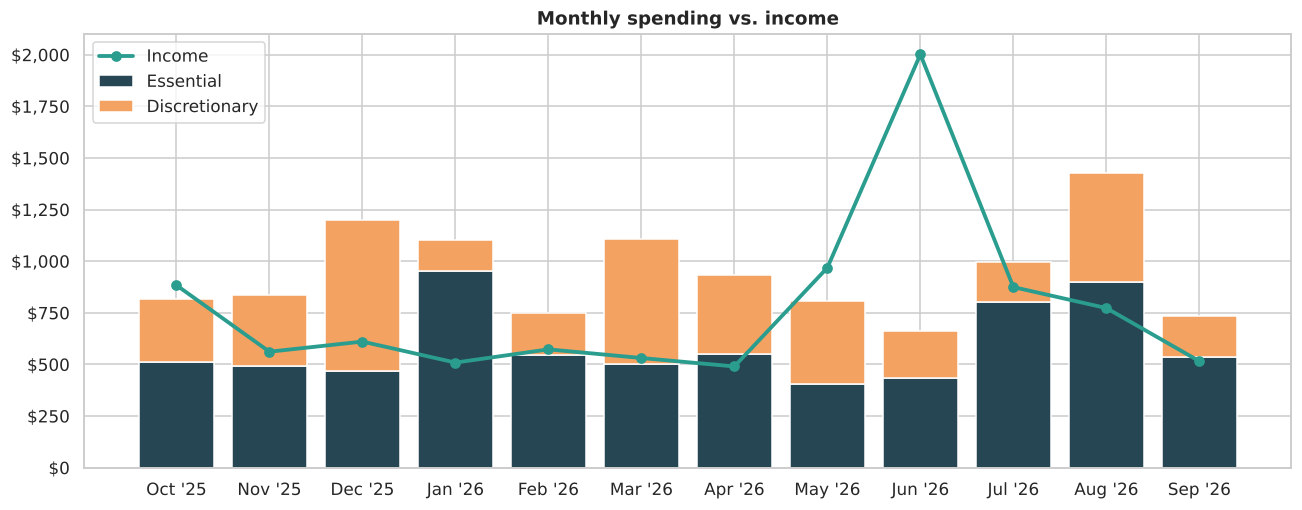

,value
Total income,9293.690000
Total spending,11379.070000
Net (income - spending),-2085.380000
Avg monthly spending,948.255833
Essential share,0.624084
Months spending > income,9.000000


In [3]:
income = df[df["grp"] == "Income"].groupby("month")["amount"].sum()
spending = df[df["grp"].isin(["Essential", "Discretionary"])].groupby("month")["spend"].sum()
essential = df[df["grp"] == "Essential"].groupby("month")["spend"].sum()
discretionary = df[df["grp"] == "Discretionary"].groupby("month")["spend"].sum()
months = spending.index.strftime("%b '%y")

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.bar(months, essential, color=BLUE, label="Essential")
ax.bar(months, discretionary, bottom=essential, color=ORANGE, label="Discretionary")
ax.plot(months, income.reindex(spending.index, fill_value=0), color=GREEN, marker="o", lw=2.5, label="Income")
ax.yaxis.set_major_formatter(dollars)
ax.set(title="Monthly spending vs. income", ylabel="")
ax.legend(loc="upper left", frameon=True)
fig.tight_layout()
save(fig, "01_income_vs_spending")
plt.show()

summary = pd.Series({
    "Total income": income.sum(),
    "Total spending": spending.sum(),
    "Net (income - spending)": income.sum() - spending.sum(),
    "Avg monthly spending": spending.mean(),
    "Essential share": essential.sum() / spending.sum(),
    "Months spending > income": int((spending > income.reindex(spending.index, fill_value=0)).sum()),
})
summary.to_frame("value")

Spending was higher than income in 9 of 12 months. The biggest gaps came in December (gifts + finals), January and August (semester starts), and March (spring break). June ran a large surplus thanks to more work hours plus the camp paycheck. The pattern is seasonal: **summer income ends up covering the school year.**

## 3. Where the money goes

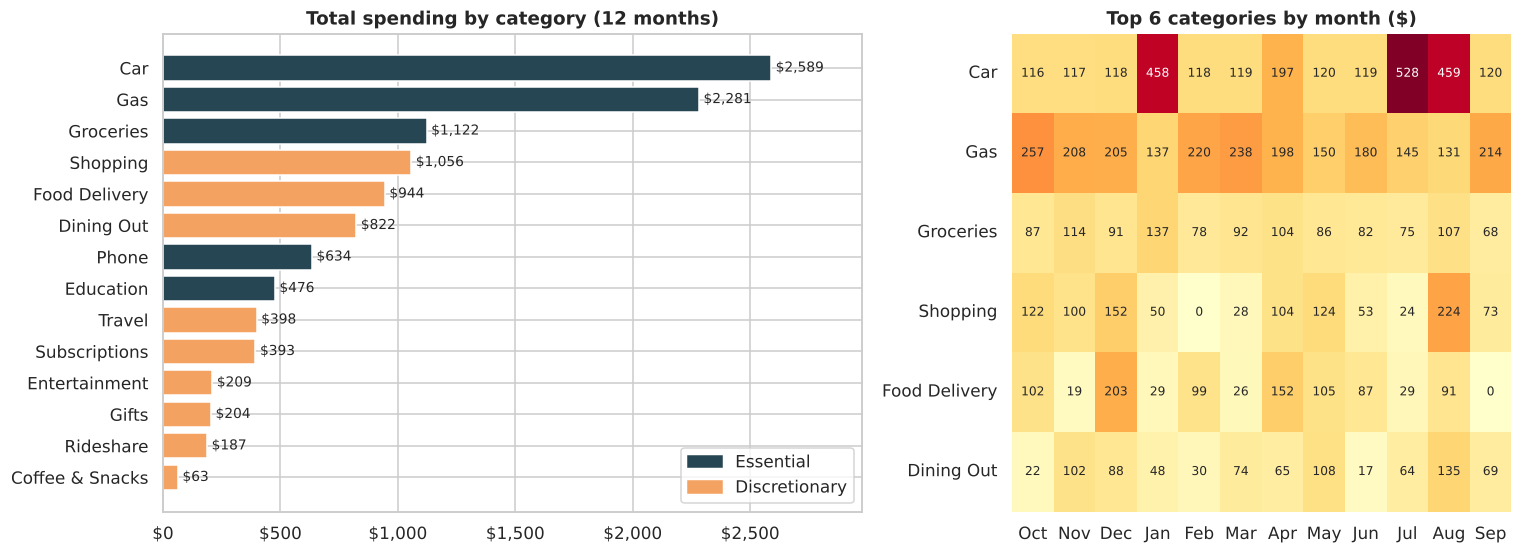

,share_of_spending
category,
Car,0.227
Gas,0.200
Groceries,0.099
Shopping,0.093
Food Delivery,0.083
Dining Out,0.072
Phone,0.056
Education,0.042


In [4]:
monthly = monthly_by_category(df)
totals = monthly.sum().sort_values()
group_of = df.drop_duplicates("category").set_index("category")["grp"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.4, 1]})
axes[0].barh(totals.index, totals.values, color=[BLUE if group_of[c] == "Essential" else ORANGE for c in totals.index])
for y, v in enumerate(totals.values):
    axes[0].text(v + 20, y, f"${v:,.0f}", va="center", fontsize=9)
axes[0].xaxis.set_major_formatter(dollars)
axes[0].set(title="Total spending by category (12 months)", xlim=(0, totals.max() * 1.15))
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE)],
               labels=["Essential", "Discretionary"], loc="lower right")

share = monthly.div(monthly.sum(axis=1), axis=0)
top = totals.index[::-1][:6]
heat = monthly[top].T
heat.columns = heat.columns.strftime("%b")
sns.heatmap(heat, cmap="YlOrRd", annot=True, fmt=".0f", cbar=False, ax=axes[1], annot_kws={"size": 8})
axes[1].set(title="Top 6 categories by month ($)", xlabel="", ylabel="")
fig.tight_layout()
save(fig, "02_spending_by_category")
plt.show()

(totals.sort_values(ascending=False) / totals.sum()).round(3).to_frame("share_of_spending").head(8)

Getting to campus is the biggest cost: **car (insurance, repairs, parking permits) and gas make up 43% of all spending.** On the food side, **eating out in all forms (delivery $944, restaurants $822, coffee $63) cost $1,829, about 1.6x what went to groceries ($1,122).**

## 4. Month-over-month increases

A category is flagged when it rises **at least 30% and at least $40** from the previous month. Requiring both filters out noise from small categories ($5 → $10) and normal swings in big ones.

In [5]:
flags = flag_increases(monthly)
flags_view = flags.assign(month=flags["month"].astype(str),
                          pct_change=flags["pct_change"].map(lambda v: "new" if pd.isna(v) else f"+{v:.0%}"))
flags_view.round(0).head(12)

,month,category,previous,current,change,pct_change
126,2026-07,Car,119.0,528.0,409.0,+344%
83,2026-03,Travel,0.0,398.0,398.0,new
42,2026-01,Car,118.0,458.0,340.0,+287%
35,2025-12,Gifts,0.0,204.0,204.0,new
151,2026-08,Shopping,24.0,224.0,200.0,+829%
33,2025-12,Food Delivery,19.0,203.0,184.0,+946%
45,2026-01,Education,0.0,166.0,166.0,new
143,2026-08,Education,0.0,150.0,150.0,new
89,2026-04,Food Delivery,26.0,152.0,126.0,+482%
160,2026-09,Gas,131.0,214.0,83.0,+63%


Most flags are **predictable**: parking permits and textbooks at each semester start, December gifts, spring-break travel, back-to-school shopping in August, and food delivery around finals. These should be budgeted ahead of time instead of treated as surprises. The **July car repair ($412 for tires)** is the one true surprise and makes the case for a small car emergency fund.

## 5. Recurring charges and subscriptions

Recurring charges are detected automatically: same merchant, charged roughly every 25-35 days, with an amount that varies less than 5%.

In [6]:
recurring = detect_recurring(df)
recurring

,merchant,category,monthly_cost,months_charged,first_charge,last_charge,active,annual_cost
0,GEICO,Car,117.68,12,2025-10-27,2026-09-27,True,1412.16
1,VERIZON WIRELESS PAYMENTS,Phone,52.40,12,2025-10-03,2026-09-03,True,628.80
2,PLANET FITNESS CLUB FEE,Subscriptions,15.00,8,2026-02-18,2026-09-18,True,180.00
3,HULU,Subscriptions,9.99,9,2025-10-25,2026-06-25,False,119.88
4,NETFLIX.COM,Subscriptions,7.99,12,2025-10-12,2026-09-12,True,95.88
5,SPOTIFY USA,Subscriptions,6.29,12,2025-10-07,2026-09-07,True,75.48
6,APPLE.COM/BILL ICLOUD,Subscriptions,0.99,12,2025-10-21,2026-09-21,True,11.88


In [7]:
subs = recurring[recurring["category"] == "Subscriptions"]
fixed = recurring[recurring["category"] != "Subscriptions"]
print(f"Fixed bills (insurance, phone):  ${fixed.loc[fixed['active'], 'annual_cost'].sum():,.0f}/year")
print(f"Active subscriptions:            ${subs.loc[subs['active'], 'annual_cost'].sum():,.0f}/year "
      f"({subs['active'].sum()} services)")
cancelled = subs[~subs["active"]]
for _, r in cancelled.iterrows():
    print(f"Cancelled: {r['merchant'].title()} (last charged {r['last_charge']}), saving ${r['annual_cost']:,.0f}/year")

Fixed bills (insurance, phone):  $2,041/year
Active subscriptions:            $363/year (4 services)
Cancelled: Hulu (last charged 2026-06-25), saving $120/year


The detector finds every recurring charge, including the Hulu subscription that stopped in July. Subscriptions total about $360/year, which is small compared with eating out. They're still worth reviewing every year, since they renew without any decision being made.

## 6. Discretionary spending deep dive

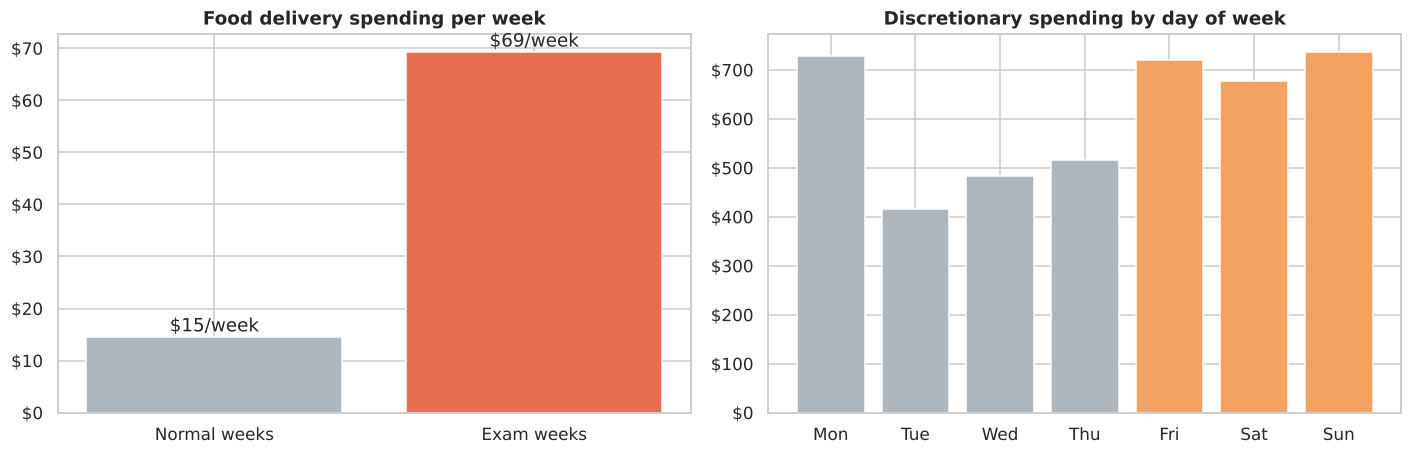

Food delivery during exam weeks: $69/week vs $15/week normally (4.7x)
Friday-Sunday share of discretionary spending: 50%


In [8]:
exam_weeks = [("2025-12-08", "2025-12-19"), ("2026-05-04", "2026-05-15")]
is_exam = np.zeros(len(df), dtype=bool)
for a, b in exam_weeks:
    is_exam |= df["date"].between(a, b).to_numpy()
delivery = df[df["category"] == "Food Delivery"]
exam_days = sum((pd.Timestamp(b) - pd.Timestamp(a)).days + 1 for a, b in exam_weeks)
other_days = (df["date"].max() - df["date"].min()).days + 1 - exam_days
exam_rate = delivery[is_exam[delivery.index]]["spend"].sum() / exam_days * 7
normal_rate = delivery[~is_exam[delivery.index]]["spend"].sum() / other_days * 7

dow = (df[df["grp"] == "Discretionary"].assign(day=lambda d: d["date"].dt.day_name())
       .groupby("day")["spend"].sum()
       .reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].bar(["Normal weeks", "Exam weeks"], [normal_rate, exam_rate], color=[GRAY, RED])
for x, v in enumerate([normal_rate, exam_rate]):
    axes[0].text(x, v + 1, f"${v:,.0f}/week", ha="center")
axes[0].yaxis.set_major_formatter(dollars)
axes[0].set(title="Food delivery spending per week")
axes[1].bar([d[:3] for d in dow.index], dow.values, color=[GRAY] * 4 + [ORANGE] * 3)
axes[1].yaxis.set_major_formatter(dollars)
axes[1].set(title="Discretionary spending by day of week")
fig.tight_layout()
save(fig, "03_discretionary_patterns")
plt.show()

weekend_share = dow[["Friday", "Saturday", "Sunday"]].sum() / dow.sum()
print(f"Food delivery during exam weeks: ${exam_rate:,.0f}/week vs ${normal_rate:,.0f}/week normally "
      f"({exam_rate / normal_rate:.1f}x)")
print(f"Friday-Sunday share of discretionary spending: {weekend_share:.0%}")

Two behavior patterns stand out: **food delivery spending jumps about 4.7x during exam weeks** (stress plus no time to cook), and **Friday through Sunday account for half of discretionary spending**. Both point to specific, timed habits rather than general overspending, which makes them easier to change.

## 7. Forecasting the next 3 months

With only 12 months of history, a complex model would overfit. Instead, I compare simple, explainable methods using a **rolling backtest**: for each of the last 6 months, forecast it using only the months before it, then measure the error.

- **Last month:** next month = this month
- **Trailing 3-month average**
- **Historical average:** average of all prior months
- **Baseline + calendar:** median of "normal" months plus known scheduled costs (textbooks, permit, gifts) in the months they occur

In [9]:
total = spending.copy()
one_offs = {1: 620, 8: 620, 12: 200}  # textbooks + parking permit in Jan & Aug, gifts in Dec

def baseline_calendar(history):
    nxt = (history.index[-1] + 1).month
    normal = history[[m.month not in one_offs for m in history.index]]
    return normal.median() + one_offs.get(nxt, 0)

methods = {
    "Last month": lambda h: h.iloc[-1],
    "Trailing 3-month avg": lambda h: h.iloc[-3:].mean(),
    "Historical average": lambda h: h.mean(),
    "Baseline + calendar": baseline_calendar,
}
bt = backtest(total, methods, start=6)
scores = (bt.groupby("method")["abs_error"].mean().sort_values().round(0)
          .to_frame("mean_abs_error ($)"))
scores["error_pct_of_avg_month"] = (scores["mean_abs_error ($)"] / total.mean()).round(3)
scores

,mean_abs_error ($),error_pct_of_avg_month
method,,
Baseline + calendar,99.0,0.104
Historical average,216.0,0.228
Trailing 3-month avg,260.0,0.274
Last month,318.0,0.335


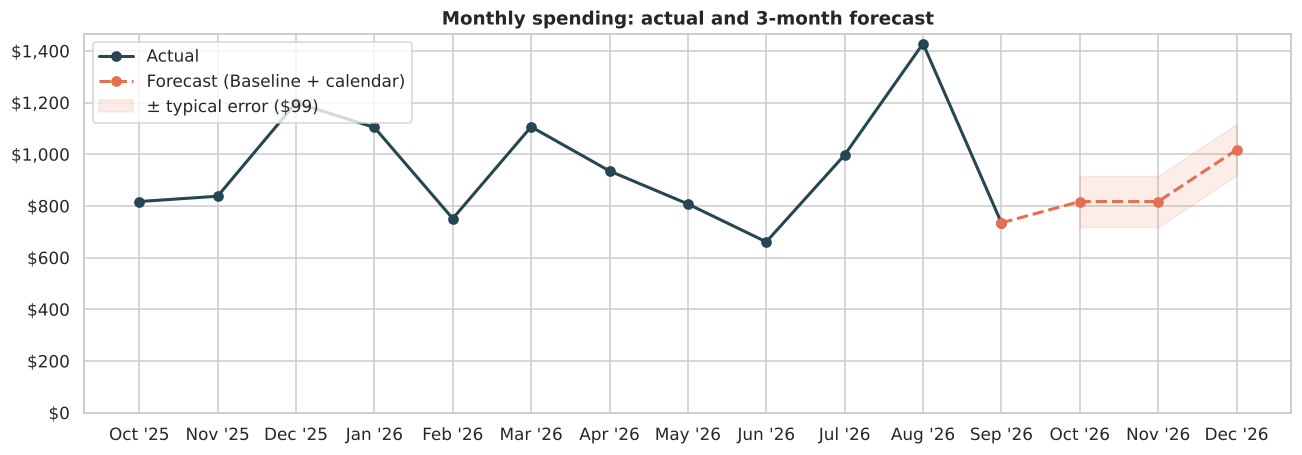

,forecast_spending
2026-10,817.0
2026-11,817.0
2026-12,1017.0


In [10]:
best = scores.index[0]
future_idx = pd.period_range(total.index[-1] + 1, periods=3, freq="M")
history = total.copy()
forecast = []
for m in future_idx:
    f = methods[best](history)
    forecast.append(f)
    history.loc[m] = f
forecast = pd.Series(forecast, index=future_idx)
err = scores.loc[best, "mean_abs_error ($)"]

fig, ax = plt.subplots(figsize=(12, 4.3))
ax.plot(total.index.strftime("%b '%y"), total.values, marker="o", color=BLUE, lw=2, label="Actual")
fx = [total.index[-1].strftime("%b '%y")] + list(forecast.index.strftime("%b '%y"))
fy = [total.iloc[-1]] + list(forecast.values)
ax.plot(fx, fy, marker="o", ls="--", color=RED, lw=2, label=f"Forecast ({best})")
ax.fill_between(fx[1:], forecast - err, forecast + err, color=RED, alpha=0.12, label=f"± typical error (${err:,.0f})")
ax.yaxis.set_major_formatter(dollars)
ax.set(title="Monthly spending: actual and 3-month forecast", ylim=(0, None))
ax.legend(loc="upper left")
fig.tight_layout()
save(fig, "04_forecast")
plt.show()
forecast.round(0).to_frame("forecast_spending")

Adding known calendar costs to a "normal month" baseline beats generic averages, because most of the volatility here comes from **scheduled** costs (semester starts, holidays), not randomness. The forecast expects a December bump from gifts.

## 8. Savings scenarios

Realistic changes, each tied to a finding above, measured against the actual 12 months:

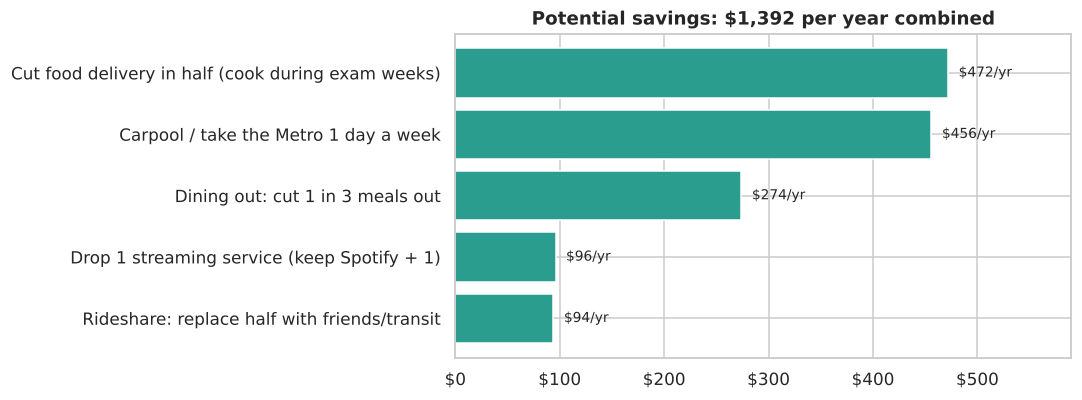

Actual net for the year:      $-2,085
Net with all changes:         $-693


,change,annual_savings
0,Cut food delivery in half (cook during exam we...,472.0
2,Carpool / take the Metro 1 day a week,456.0
1,Dining out: cut 1 in 3 meals out,274.0
4,Drop 1 streaming service (keep Spotify + 1),96.0
3,Rideshare: replace half with friends/transit,94.0
total,All changes combined,1392.0


In [11]:
annual = monthly.sum()
scenarios = pd.DataFrame([
    {"change": "Cut food delivery in half (cook during exam weeks)", "annual_savings": annual["Food Delivery"] * 0.5},
    {"change": "Dining out: cut 1 in 3 meals out", "annual_savings": annual["Dining Out"] / 3},
    {"change": "Carpool / take the Metro 1 day a week", "annual_savings": annual["Gas"] * 0.2},
    {"change": "Rideshare: replace half with friends/transit", "annual_savings": annual["Rideshare"] * 0.5},
    {"change": "Drop 1 streaming service (keep Spotify + 1)", "annual_savings": 7.99 * 12},
]).round(0).sort_values("annual_savings", ascending=False)
scenarios.loc["total"] = ["All changes combined", scenarios["annual_savings"].sum()]

fig, ax = plt.subplots(figsize=(10, 3.8))
s = scenarios.iloc[:-1].iloc[::-1]
ax.barh(s["change"], s["annual_savings"], color=GREEN)
for y, v in enumerate(s["annual_savings"]):
    ax.text(v + 10, y, f"${v:,.0f}/yr", va="center", fontsize=9)
ax.xaxis.set_major_formatter(dollars)
ax.set(title=f"Potential savings: ${scenarios.loc['total', 'annual_savings']:,.0f} per year combined",
       xlim=(0, s["annual_savings"].max() * 1.25))
fig.tight_layout()
save(fig, "05_savings_scenarios")
plt.show()

net = income.sum() - spending.sum()
saved = scenarios.loc["total", "annual_savings"]
print(f"Actual net for the year:      ${net:,.0f}")
print(f"Net with all changes:         ${net + saved:,.0f}")
scenarios

In [12]:
# Suggested monthly budget (median month for regular categories, yearly total / 12 for lumpy ones)
budget = budget_report()
print(f"Suggested monthly budget: ${budget['suggested_budget'].sum():,.0f}")
budget

Suggested monthly budget: $860


,avg_month,median_month,max_month,budget_type,suggested_budget
category,,,,,
Car,216.0,119.0,528.0,monthly,120.0
Gas,190.0,201.0,257.0,monthly,200.0
Groceries,94.0,89.0,137.0,monthly,90.0
Shopping,88.0,87.0,224.0,monthly,85.0
Food Delivery,79.0,89.0,203.0,monthly,90.0
Dining Out,69.0,67.0,135.0,monthly,65.0
Phone,53.0,52.0,56.0,monthly,50.0
Education,40.0,0.0,166.0,sinking fund,40.0
Travel,33.0,0.0,398.0,sinking fund,35.0


## 9. Key findings

1. **The tracker categorized 100% of 390 transactions automatically** across 14 spending categories, using keyword rules that also handle messy bank descriptions like `UBER *EATS PENDING` and `TST* NANDOS PERI PERI`.
2. **Spending ($11,379) outran income ($9,294) by about $2,085 over the year.** 9 of 12 months ran a deficit, and summer income covered the school year.
3. **Commuting is the biggest cost.** Car (insurance, repairs, parking permits) and gas make up **43% of all spending**.
4. **Eating out cost 1.6x groceries:** $1,829 on delivery, restaurants, and coffee vs. $1,122 on groceries. Food delivery jumps about **4.7x during exam weeks**.
5. **Most "spikes" are predictable.** Semester starts, December gifts, spring break, and finals explain most month-over-month jumps. The only real surprise was a $412 tire replacement in July.
6. **Recurring charges total about $2,400/year:** $2,041 in fixed bills and $363 in subscriptions across 4 active services. The detector also caught a cancelled subscription (Hulu).
7. **A simple, calendar-aware forecast works best.** "Normal month + scheduled costs" had the lowest backtest error (about $99/month, ~10% of an average month), less than half the error of a historical average.
8. **Five realistic changes would save about $1,400/year**, cutting the annual shortfall by two-thirds. Halving food delivery and carpooling once a week are the biggest levers.

**Limitations:** this analysis uses sample data, so the specific dollar amounts describe a realistic student profile, not a real person. Keyword categorization needs new rules when new merchants appear (the `uncategorized` command lists them). With only 12 months of history, the forecast can't learn year-over-year seasonality yet.